# Assignment 5: Hierarchical Clustering – Agglomerative, Divisive, Linkage Methods and Dendrograms

## Introduction
In this assignment I apply hierarchical clustering to the Wholesale Customers dataset from the UCI Machine Learning Repository. It contains the annual spending of 440 clients of a Portuguese wholesale distributor across 6 product categories, measured in monetary units (m.u.), plus each client's channel (Horeca or Retail) and region.

Hierarchical clustering builds a tree of clusters instead of a single flat grouping, so I can see how clients group together at every level of detail.

My steps:
- Explain agglomerative vs divisive clustering (Task 1)
- Calculate and compare Euclidean, Manhattan and Cosine distances (Task 2)
- Load and preprocess the data
- Run agglomerative clustering with Single, Complete, Average and Ward linkage and draw dendrograms (Task 3)
- Analyze how the linkage method changes the results (Task 4)
- Run divisive clustering and compare it with agglomerative
- Calculate the cophenetic correlation coefficient for each linkage (Task 5)
- Discuss and demonstrate connectivity constraints (Task 6)
- Write a conclusion

## Task 1 – Agglomerative vs Divisive Clustering

## Task 1 – Agglomerative vs Divisive Clustering

### Agglomerative clustering (bottom-up)
- It starts with every point as its own cluster (440 clusters for 440 clients).
- At each step it merges the two closest clusters, until only one cluster is left.
- How "closest" is measured between clusters depends on the linkage method (Single, Complete, Average or Ward).
- The full merge history is shown as a dendrogram, and I can cut it at any height to get the number of clusters I want.

### Divisive clustering (top-down)
- It starts with all points in one big cluster.
- At each step it splits a cluster into two, until every point is alone or a stopping rule is reached.
- Classic divisive clustering (DIANA) checks many possible splits, so it is very slow. In practice, a common approach is Bisecting K-means, which uses K-means with k = 2 to split the largest (or worst) cluster each time.

### Key differences
- Direction: agglomerative works from small to big, divisive from big to small.
- Focus: agglomerative is better at finding fine, local groups because its early decisions are based on nearby points. Divisive is better at finding the big, global structure because its first decisions look at the whole dataset.
- Speed: basic agglomerative clustering needs the distance between every pair of points, so it gets slow on large data. Bisecting K-means is fast because each split is just a K-means with k = 2.
- Both are greedy: once a merge or split happens, it cannot be undone.

### When each method might be preferred
Agglomerative is preferred when:
- The dataset is small or medium-sized and I want the full detailed dendrogram (for example, a few hundred customers).
- I care about small, tight groups, such as finding near-duplicate products in a catalogue or very similar customers for look-alike targeting.
- I want to try different linkage methods and distance metrics.

Divisive is preferred when:
- I mainly need the top few levels of the tree, such as splitting a market first into 2 or 3 big segments and then splitting only the large ones further.
- The dataset is large, so building the full bottom-up tree would be too slow (for example, millions of website visitors).
- The big picture matters more than small details, such as organizing a large document collection into broad topics first and subtopics later.

## 1. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, BisectingKMeans
from sklearn.neighbors import kneighbors_graph
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform, euclidean, cityblock, cosine

np.random.seed(42)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [5]:
wholesale_df = pd.read_csv("Wholesale customers data.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
channel_names = {1: "Horeca", 2: "Retail"}
channel_true = wholesale_df["Channel"].values

print("Shape:", wholesale_df.shape)
print("Missing values:", wholesale_df.isna().sum().sum(), "| Duplicates:", wholesale_df.duplicated().sum())


Shape: (440, 8)
Missing values: 0 | Duplicates: 0


In [6]:
X_log = np.log1p(wholesale_df[spend_cols])
X_scaled = StandardScaler().fit_transform(X_log)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Scaled feature matrix:", X_scaled.shape)
print("PCA explained variance (2 components):", pca.explained_variance_ratio_.sum().round(3))

Scaled feature matrix: (440, 6)
PCA explained variance (2 components): 0.713


### Interpretation – Loading and Preprocessing
- The dataset has 440 clients and 8 columns, with no missing values and no duplicates.
- I used the same preprocessing as Assignment 4: I kept only the 6 spending columns, applied a log transform to reduce the strong right skew and extreme buyers, and then standardized every column to mean 0 and standard deviation 1. This matters because hierarchical clustering is based on distances, so without it the largest and most skewed categories would dominate.
- The final feature matrix is 440 × 6.
- PCA with 2 components keeps 71.3% of the information, so the 2D plots will be a fairly accurate picture of the clusters.
- Channel (Horeca or Retail) is kept aside and only used to check the results, not to build the clusters.

## Task 2 – Euclidean, Manhattan and Cosine Distances

In [7]:
pts = {"A": np.array([1, 2]), "B": np.array([4, 6]), "C": np.array([2, 4])}
pairs = [("A", "B"), ("A", "C"), ("B", "C")]

hand_rows = []
for p1, p2 in pairs:
    a, b = pts[p1], pts[p2]
    hand_rows.append({"pair": f"{p1}{tuple(a)} – {p2}{tuple(b)}",
                      "Euclidean": round(euclidean(a, b), 4),
                      "Manhattan": round(cityblock(a, b), 4),
                      "Minkowski p=3": round(pdist([a, b], metric="minkowski", p=3)[0], 4),
                      "Cosine distance": round(cosine(a, b), 4)})
print("Simple example:")
print(pd.DataFrame(hand_rows).to_string(index=False))

Simple example:
                                                     pair  Euclidean  Manhattan  Minkowski p=3  Cosine distance
A(np.int64(1), np.int64(2)) – B(np.int64(4), np.int64(6))     5.0000          7         4.4979           0.0077
A(np.int64(1), np.int64(2)) – C(np.int64(2), np.int64(4))     2.2361          3         2.0801           0.0000
B(np.int64(4), np.int64(6)) – C(np.int64(2), np.int64(4))     2.8284          4         2.5198           0.0077


In [8]:
clients = X_scaled[:5]
client_ids = [f"Client {i}" for i in range(5)]
print("\nEuclidean distances – first 5 clients (scaled data):")
display(pd.DataFrame(squareform(pdist(clients, "euclidean")), index=client_ids, columns=client_ids).round(3))
print("Manhattan distances – first 5 clients (scaled data):")
display(pd.DataFrame(squareform(pdist(clients, "cityblock")), index=client_ids, columns=client_ids).round(3))


Euclidean distances – first 5 clients (scaled data):


,Client 0,Client 1,Client 2,Client 3,Client 4
Client 0,0.000,1.723,2.384,3.470,2.596
Client 1,1.723,0.000,1.198,2.596,1.484
Client 2,2.384,1.198,0.000,2.672,1.167
Client 3,3.470,2.596,2.672,0.000,1.918
Client 4,2.596,1.484,1.167,1.918,0.000


Manhattan distances – first 5 clients (scaled data):


,Client 0,Client 1,Client 2,Client 3,Client 4
Client 0,0.000,2.609,3.984,6.338,4.529
Client 1,2.609,0.000,1.799,5.223,3.413
Client 2,3.984,1.799,0.000,5.931,2.475
Client 3,6.338,5.223,5.931,0.000,4.183
Client 4,4.529,3.413,2.475,4.183,0.000


In [9]:
d_euc = pdist(X_scaled, "euclidean")
d_man = pdist(X_scaled, "cityblock")
print(f"All {len(d_euc):,} client pairs:")
print(f"  Mean Euclidean: {d_euc.mean():.3f} | Mean Manhattan: {d_man.mean():.3f}")
print(f"  Average ratio Manhattan / Euclidean: {(d_man / d_euc).mean():.3f}")
print(f"  Correlation between the two distances: {np.corrcoef(d_euc, d_man)[0, 1]:.4f}")

All 96,580 client pairs:
  Mean Euclidean: 3.183 | Mean Manhattan: 6.598
  Average ratio Manhattan / Euclidean: 2.067
  Correlation between the two distances: 0.9733


### Interpretation – Task 2: Comparing Distances
Simple example with A = (1, 2), B = (4, 6) and C = (2, 4):
- Euclidean distance is the straight-line distance. For A and B it is √(3² + 4²) = 5.
- Manhattan distance adds up the differences along each axis, like walking a city grid. For A and B it is 3 + 4 = 7. Manhattan is always greater than or equal to Euclidean, because walking along the grid is never shorter than a straight line.
- Minkowski with p = 3 gives 4.50 for A and B. As p increases, the distance gets smaller and depends more on the single biggest difference (Manhattan 7 > Euclidean 5 > p = 3 4.50).
- Cosine distance only looks at the direction of the points, not their size. C is exactly 2 × A, so the cosine distance between A and C is 0, even though they are 2.24 units apart in Euclidean distance. In marketing terms, two customers with the same spending mix but very different budgets would look identical with cosine distance.

First 5 clients (scaled data):
- Both metrics agree that Clients 0 and 3 are the most different pair (Euclidean 3.470, Manhattan 6.338).
- However, the nearest neighbour can change. For Client 2, Euclidean says the closest client is Client 4 (1.167), but Manhattan says it is Client 1 (1.799 vs 2.475 for Client 4). Euclidean squares the differences, so one large difference counts a lot, while Manhattan adds all differences equally, so many small differences add up. Clients 2 and 4 differ slightly in many categories, while Clients 2 and 1 differ more in only a few.

All 96,580 client pairs:
- Manhattan distances are on average about 2.07 times larger than Euclidean distances (6.598 vs 3.183).
- The correlation between the two distances is 0.9733, so they rank most pairs of clients in almost the same order, but not all of them. The choice of metric can therefore still change some cluster assignments.

## Task 3 – Agglomerative Clustering with Different Linkage Methods

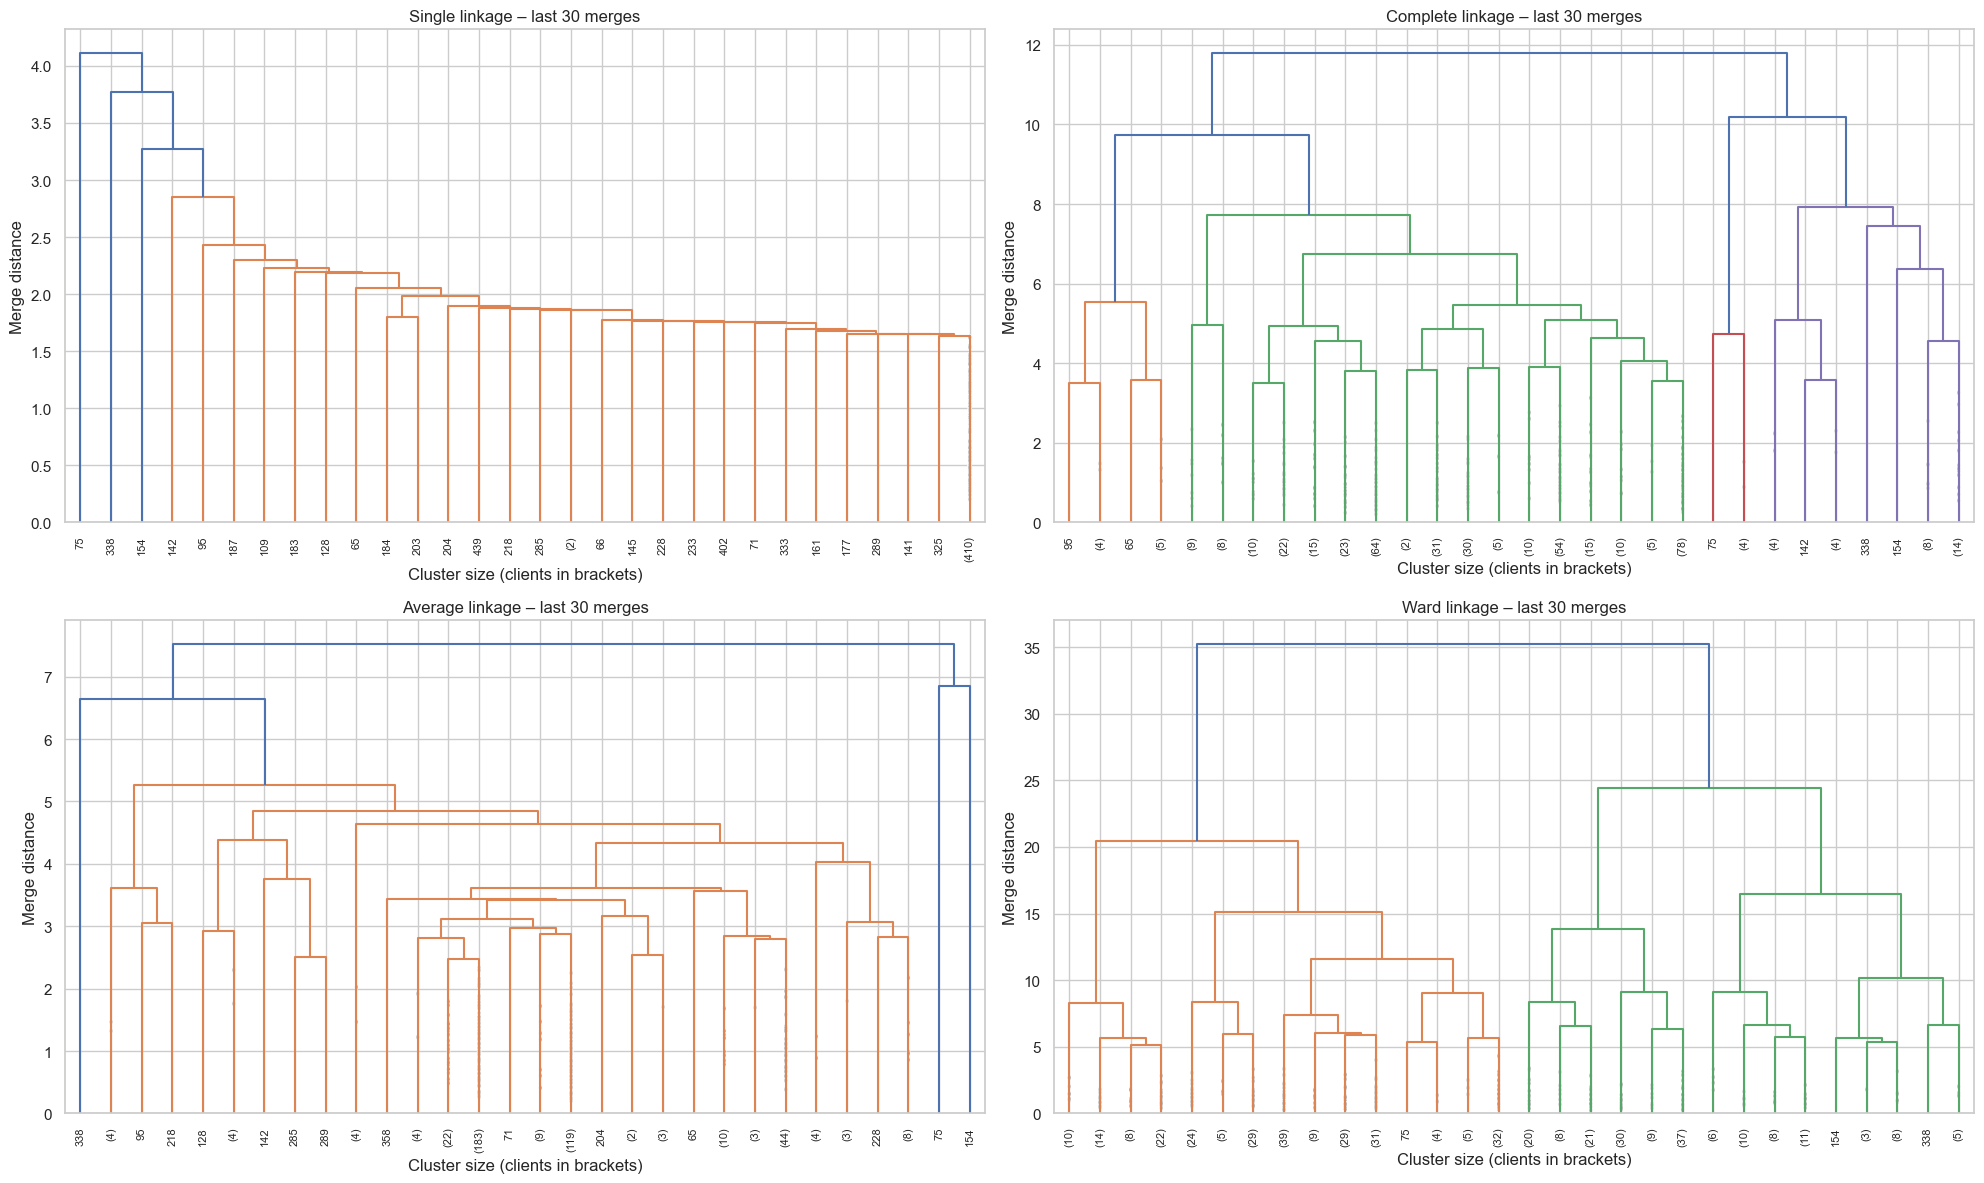

In [10]:
methods = ["single", "complete", "average", "ward"]
linkages = {}

fig, axes = plt.subplots(2, 2, figsize=(20, 12))
for ax, method in zip(axes.flatten(), methods):
    Z = linkage(X_scaled, method=method, metric="euclidean")
    linkages[method] = Z
    dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8,
               show_contracted=True, ax=ax)
    ax.set_title(f"{method.capitalize()} linkage – last 30 merges")
    ax.set_xlabel("Cluster size (clients in brackets)")
    ax.set_ylabel("Merge distance")
plt.tight_layout()
plt.show()



 linkage  k              sizes  silhouette  ARI_vs_Channel
  single  2           [439, 1]      0.5700         -0.0024
  single  4     [437, 1, 1, 1]      0.4980         -0.0070
complete  2          [402, 38]      0.3220         -0.0550
complete  4   [391, 33, 11, 5]      0.2595         -0.0315
 average  2           [438, 2]      0.5691         -0.0047
 average  4     [437, 1, 1, 1]      0.4980         -0.0070
    ward  2         [262, 178]      0.2585          0.5392
    ward  4 [208, 125, 54, 53]      0.2021          0.3897


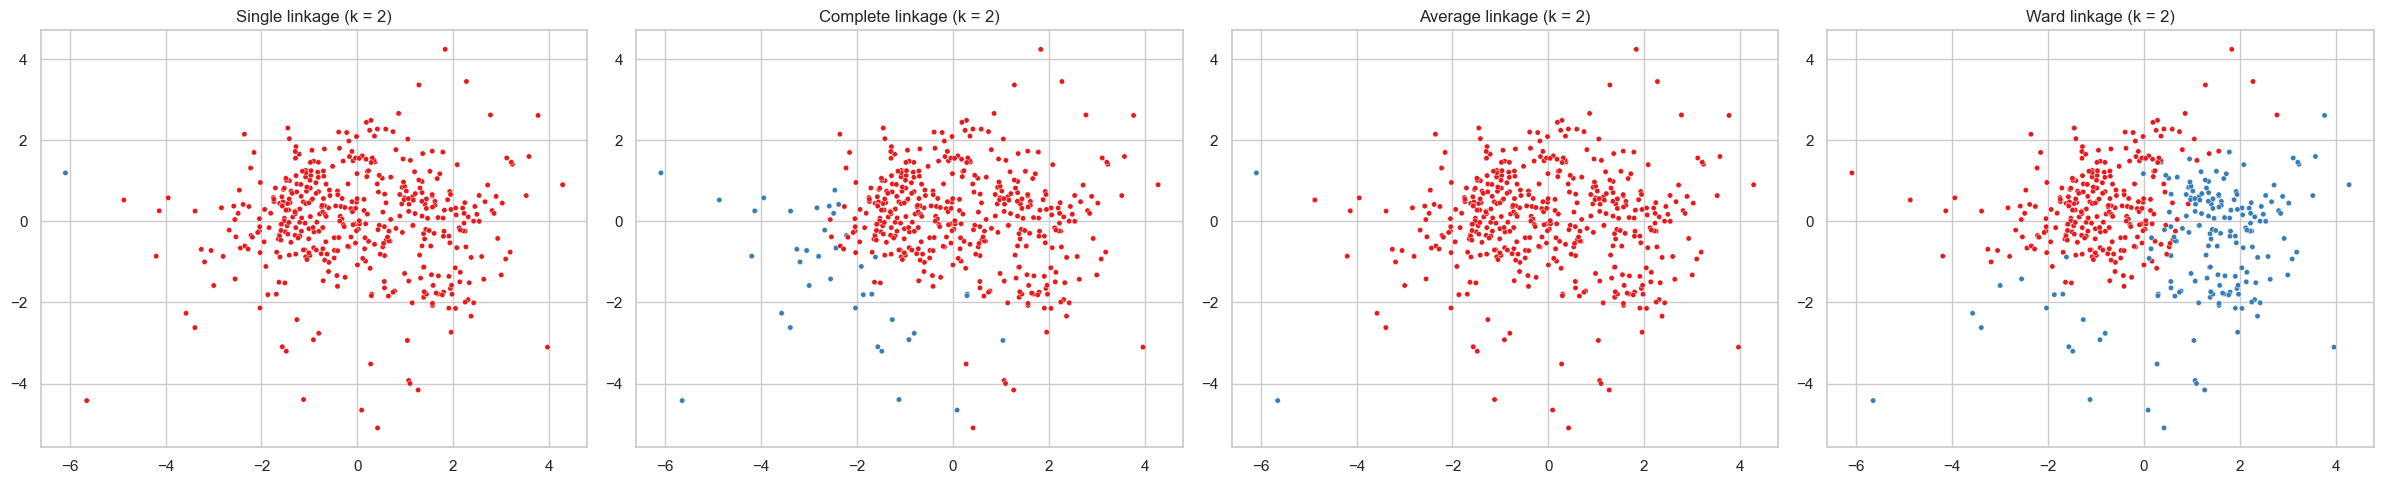

In [11]:
link_rows = []
for method, Z in linkages.items():
    for k in [2, 4]:
        labels = fcluster(Z, t=k, criterion="maxclust")
        link_rows.append({"linkage": method, "k": k,
                          "sizes": sorted(np.bincount(labels)[1:].tolist(), reverse=True),
                          "silhouette": round(silhouette_score(X_scaled, labels), 4),
                          "ARI_vs_Channel": round(adjusted_rand_score(channel_true, labels), 4)})
print(pd.DataFrame(link_rows).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, method in zip(axes, methods):
    labels = fcluster(linkages[method], t=2, criterion="maxclust")
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette="Set1", s=15, ax=ax, legend=False)
    ax.set_title(f"{method.capitalize()} linkage (k = 2)")
plt.tight_layout()
plt.show()

## Task 4 – Analysis of the Dendrograms and the Effect of Linkage

Single linkage:
- The dendrogram looks like a staircase. Most merges happen at almost the same height (about 1.6 to 2.0), and the last merges only add single clients (75, 338 and 154).
- This is the chaining effect. Single linkage measures the distance between two clusters by their closest pair of points, so one close pair is enough to join two groups. Clients connect one by one into one long chain instead of forming separate groups.
- Cutting into 2 clusters gives 439 clients vs 1 client, and 4 clusters gives 437 vs 1 vs 1 vs 1. It only separates individual outliers.

Average linkage:
- The result is very similar to single linkage: 438 vs 2 clients for k = 2, and 437 vs 1 vs 1 vs 1 for k = 4. The top of the dendrogram is again just a few outliers (338, 75 and 154) joining the main group at the end.

Complete linkage:
- Complete linkage uses the farthest pair of points, so it avoids chaining and creates more compact clusters. Its dendrogram shows more groups merging at clearly different heights.
- Its clusters are still unbalanced (402 vs 38 for k = 2, and 391, 33, 11 and 5 for k = 4). It separates groups of unusual clients at the edges of the data rather than real segments.

Ward linkage:
- Ward merges the clusters that increase the within-cluster variance the least, so it creates balanced, compact groups. Its dendrogram has a large jump at the top (from about 24.5 to 35), which clearly suggests 2 clusters.
- It is the only method with balanced clusters: 262 vs 178 for k = 2, and 208, 125, 54 and 53 for k = 4.
- Its ARI (Adjusted Rand Index) against Channel is 0.539 for k = 2, much higher than the other methods (all close to 0) and even higher than BIRCH in Assignment 4 (0.30). Ward's 2 clusters closely follow the Horeca vs Retail split. The scatter plot shows the same left vs right split as BIRCH.

Silhouette scores:
- Single (0.570) and average (0.569) have the highest silhouette scores, but this is misleading. A tiny group of 1 or 2 far-away clients against everyone else looks very well separated, but it is not a useful segmentation. Ward has a lower silhouette (0.259) but gives the only meaningful clusters.

Conclusion:
The linkage method has a huge effect on the results. Single and average linkage mainly detect outliers, complete linkage finds small edge groups, and Ward linkage finds real, balanced customer segments. For this dataset, Ward is the best choice.

## 3. Divisive Clustering (Bisecting K-means)

In [12]:
print("Outlier clients from single/average linkage:")
display(wholesale_df.loc[[75, 154, 338], ["Channel"] + spend_cols])

div_rows = []
div_labels = {}
for k in range(2, 6):
    bkm = BisectingKMeans(n_clusters=k, bisecting_strategy="largest_cluster", n_init=10, random_state=42)
    labels = bkm.fit_predict(X_scaled)
    div_labels[k] = labels
    div_rows.append({"k": k, "sizes": np.bincount(labels).tolist(),
                     "silhouette": round(silhouette_score(X_scaled, labels), 4),
                     "ARI_vs_Channel": round(adjusted_rand_score(channel_true, labels), 4)})
print(pd.DataFrame(div_rows).to_string(index=False))

Outlier clients from single/average linkage:


,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
75,1,20398,1137,3,4407,3,975
154,1,622,55,137,75,7,8
338,1,3,333,7021,15601,15,550


 k                 sizes  silhouette  ARI_vs_Channel
 2            [252, 188]      0.2903          0.5135
 3        [99, 153, 188]      0.1891          0.2624
 4    [99, 153, 74, 114]      0.1892          0.2525
 5 [99, 74, 79, 74, 114]      0.1293          0.1697


### Interpretation – Outlier Clients
The three clients that single and average linkage separated are all Horeca clients with extreme spending patterns:
- Client 75 spends 20,398 m.u. on Fresh but only 3 m.u. on Grocery and 3 m.u. on Detergents_Paper, so it buys almost no grocery or paper products at all.
- Client 154 spends very little on everything (for example, 55 m.u. on Milk, 8 m.u. on Delicassen and 7 m.u. on Detergents_Paper).
- Client 338 spends only 3 m.u. on Fresh but 15,601 m.u. on Frozen, so it is a frozen-food specialist.
After the log transform, these near-zero values become extreme low values, so these clients are far away from everyone else. This is why single and average linkage separate them first.


Divisive (k=2) vs Agglomerative Ward (k=2):


Ward,1,2
Divisive,,
0,235,17
1,27,161


Agreement between the two (ARI): 0.6389


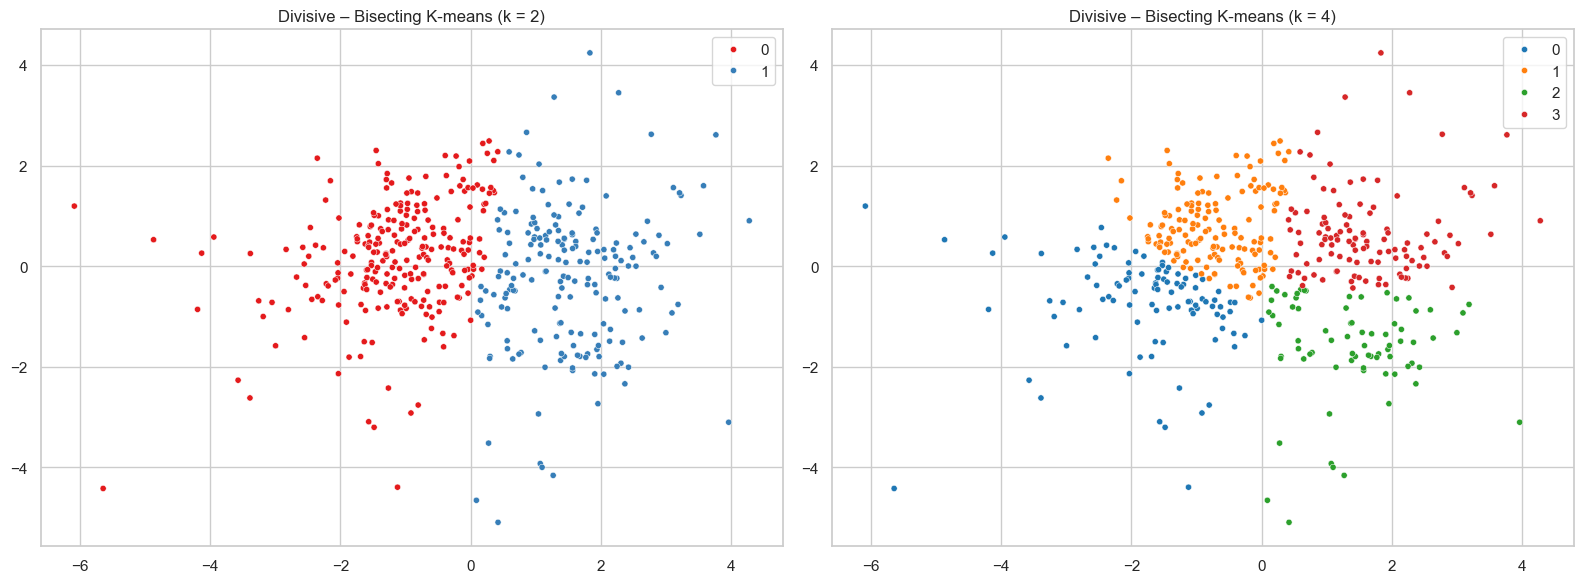

In [13]:
ward_2 = fcluster(linkages["ward"], t=2, criterion="maxclust")
print("\nDivisive (k=2) vs Agglomerative Ward (k=2):")
display(pd.crosstab(div_labels[2], ward_2, rownames=["Divisive"], colnames=["Ward"]))
print(f"Agreement between the two (ARI): {adjusted_rand_score(div_labels[2], ward_2):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=div_labels[2], palette="Set1", s=20, ax=axes[0])
axes[0].set_title("Divisive – Bisecting K-means (k = 2)")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=div_labels[4], palette="tab10", s=20, ax=axes[1])
axes[1].set_title("Divisive – Bisecting K-means (k = 4)")
plt.tight_layout()
plt.show()

### Interpretation – Divisive Clustering (Bisecting K-means)
- I used Bisecting K-means as the divisive (top-down) method. It starts with all 440 clients in one cluster and keeps splitting the largest cluster into two using K-means with k = 2.
- With 2 clusters, it split the clients into 252 and 188, with a silhouette score of 0.290 and an ARI (Adjusted Rand Index) against Channel of 0.514. This is very close to agglomerative Ward (262 vs 178, silhouette 0.259, ARI 0.539).
- The two methods agree on 396 of the 440 clients (90%), and their ARI against each other is 0.639. Top-down and bottom-up clustering found almost the same two groups, which strongly suggests that this split is real.
- Divisive clustering gave slightly tighter clusters (higher silhouette), while Ward matched the Horeca vs Retail split slightly better.
- The divisive splits are nested: at k = 3 the 252 group splits into 99 and 153 while the 188 group stays the same, at k = 4 the 188 group splits into 74 and 114, and at k = 5 the 153 group splits into 79 and 74. Each step only divides one existing cluster, which is how top-down clustering builds its tree.
- The silhouette score drops sharply after k = 2 (from 0.290 to 0.189), so 2 clusters is the most natural level for this dataset with both methods.

## Task 5 – Cophenetic Correlation Coefficient

In [14]:
original_dist = pdist(X_scaled, metric="euclidean")
coph_rows = []
coph_dists = {}

for method, Z in linkages.items():
    c, coph_d = cophenet(Z, original_dist)
    coph_dists[method] = coph_d
    coph_rows.append({"linkage": method, "cophenetic_correlation": round(c, 4)})

coph_table = pd.DataFrame(coph_rows).sort_values("cophenetic_correlation", ascending=False)
print(coph_table.to_string(index=False))

 linkage  cophenetic_correlation
 average                  0.7452
complete                  0.6536
  single                  0.6493
    ward                  0.4841


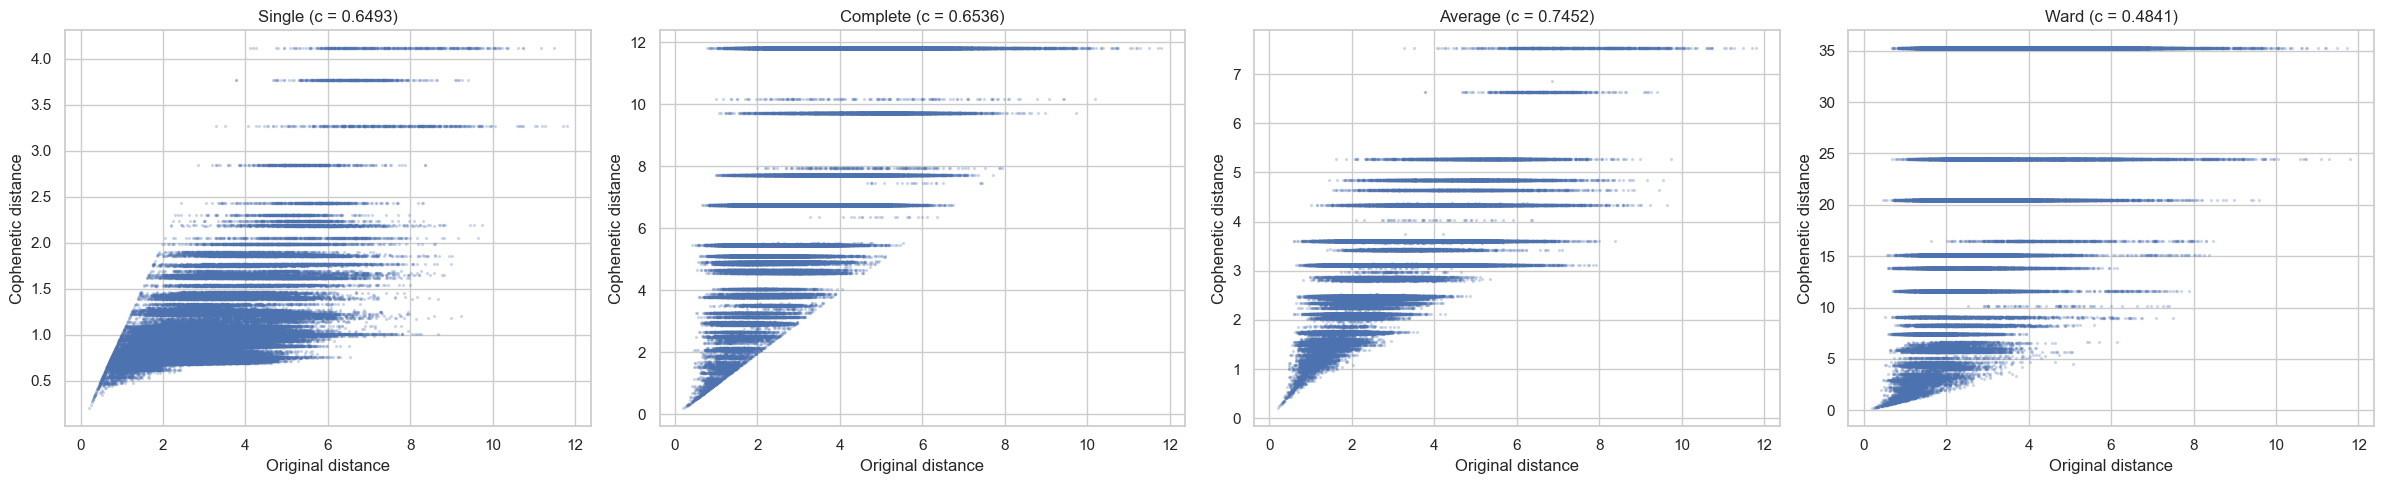

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, method in zip(axes, methods):
    ax.scatter(original_dist, coph_dists[method], s=2, alpha=0.2)
    c_val = coph_table.loc[coph_table["linkage"] == method, "cophenetic_correlation"].values[0]
    ax.set_title(f"{method.capitalize()} (c = {c_val})")
    ax.set_xlabel("Original distance")
    ax.set_ylabel("Cophenetic distance")
plt.tight_layout()
plt.show()

## Task 5 – Cophenetic Correlation Coefficient

### What it is
The cophenetic distance between two clients is the height on the dendrogram where they first end up in the same cluster. The cophenetic correlation coefficient (c) is the correlation between these dendrogram distances and the real distances between clients. A value close to 1 means the dendrogram is a faithful summary of the real distances, and values below about 0.7 are usually considered weak. It is used to check how well a hierarchical clustering represents the original data, and to compare linkage methods or distance metrics.

### My results
- Average linkage has the highest cophenetic correlation (0.7452), and it is the only method above 0.7. In its scatter plot, the dendrogram distances follow the real distances most closely. This makes sense because average linkage uses the average of all distances between two clusters, which is close to what the cophenetic correlation measures.
- Complete (0.6536) and single (0.6493) linkage are in the middle. Single linkage compresses the large distances: its highest merge is only about 4.1, while some clients are about 12 apart. Because of chaining, clients that are far apart can end up joined at a low height.
- Ward linkage has the lowest cophenetic correlation (0.4841). Its merge heights go up to about 35, much higher than the real distances, because Ward's heights measure the increase in within-cluster variance, not the distance itself. Its scatter plot shows a few flat bands instead of a diagonal.

### Significance
Ward gave the most useful clusters in Task 3 (balanced groups, ARI 0.539 against Channel) but has the lowest cophenetic correlation. This shows that the cophenetic correlation measures how faithfully the dendrogram keeps the pairwise distances, not how useful or meaningful the clusters are. It is a good check of whether a dendrogram is an honest picture of the data, but it should be used together with other measures (like silhouette, ARI or business meaning) when choosing a clustering method.

## Task 6 – Connectivity Constraints

In [16]:
conn_rows = []
for n_nb in [None, 5, 10, 30]:
    for method in ["ward", "average"]:
        if n_nb is None:
            conn = None
        else:
            conn = kneighbors_graph(X_scaled, n_neighbors=n_nb, include_self=False)
        model = AgglomerativeClustering(n_clusters=2, linkage=method, connectivity=conn)
        labels = model.fit_predict(X_scaled)
        conn_rows.append({"connectivity": "none" if n_nb is None else f"{n_nb}-NN graph",
                          "linkage": method,
                          "sizes": sorted(np.bincount(labels).tolist(), reverse=True),
                          "silhouette": round(silhouette_score(X_scaled, labels), 4),
                          "ARI_vs_Channel": round(adjusted_rand_score(channel_true, labels), 4)})
print(pd.DataFrame(conn_rows).to_string(index=False))

connectivity linkage      sizes  silhouette  ARI_vs_Channel
        none    ward [262, 178]      0.2585          0.5392
        none average   [438, 2]      0.5691         -0.0047
  5-NN graph    ward [234, 206]      0.2631          0.4152
  5-NN graph average   [439, 1]      0.5162         -0.0024
 10-NN graph    ward [262, 178]      0.2585          0.5392
 10-NN graph average   [439, 1]      0.5700         -0.0024
 30-NN graph    ward [262, 178]      0.2585          0.5392
 30-NN graph average   [439, 1]      0.5700         -0.0024


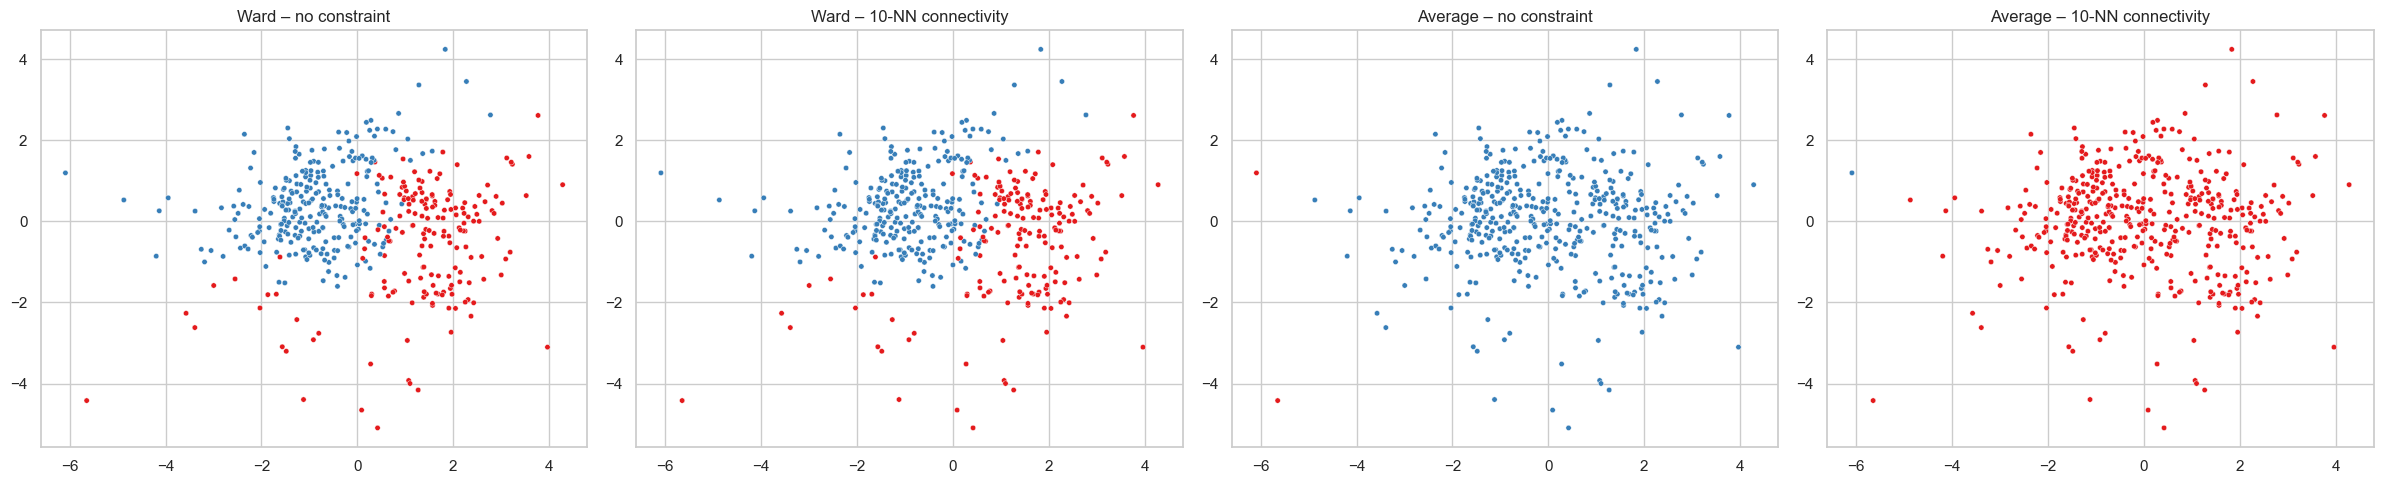

In [17]:
conn_10 = kneighbors_graph(X_scaled, n_neighbors=10, include_self=False)
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
settings = [("ward", None), ("ward", conn_10), ("average", None), ("average", conn_10)]
for ax, (method, conn) in zip(axes, settings):
    labels = AgglomerativeClustering(n_clusters=2, linkage=method, connectivity=conn).fit_predict(X_scaled)
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette="Set1", s=15, ax=ax, legend=False)
    ax.set_title(f"{method.capitalize()} – {'no constraint' if conn is None else '10-NN connectivity'}")
plt.tight_layout()
plt.show()

## Task 6 – Connectivity Constraints

### What they are
Normally, hierarchical clustering can merge any two clusters, no matter where they are. A connectivity constraint gives the algorithm a graph that says which points are neighbours, and it is only allowed to merge clusters that are connected in this graph. This forces clusters to grow only through neighbouring points, and it also makes the algorithm faster on large datasets, because it only needs to check connected pairs instead of every possible pair.

### My results
I built k-nearest-neighbour graphs (each client linked to its 5, 10 or 30 closest clients) and compared them with no constraint, for Ward and average linkage with 2 clusters.
- Ward with a 10-NN or 30-NN graph gave exactly the same result as without a constraint (262 vs 178 clients, ARI 0.539 against Channel). Ward was already merging neighbouring groups, so the constraint did not block any of its merges.
- Only the strict 5-NN graph changed Ward's result, to 234 vs 206 clients. The clusters became more balanced and the silhouette score went up slightly (0.2631 vs 0.2585), but the match with Channel dropped (ARI 0.415). With so few links, some of the merges Ward wanted were not allowed, so it built the tree differently.
- The constraint did not fix average linkage. It still separated a single outlier client from everyone else (439 vs 1). An isolated client has only a few links to the others, so it is still the last one to join. Connectivity constraints do not solve outlier problems.
- In this dataset there is no natural structure (like location or time) for the constraint to follow, so its effect is small.

### Real-world example
A wholesale distributor wants to create delivery or sales territories by clustering its clients. Clustering on spending alone could put a client in Lisbon and a client in Oporto in the same group. With a connectivity constraint based on geography (for example, linking each client only to clients in neighbouring postal codes), the algorithm can only merge clients that are next to each other on the map. Each final cluster is then one connected area that a single sales rep or delivery truck can cover, while still grouping clients with similar needs.

Other common uses:
- Image segmentation: each pixel is only connected to the pixels next to it, so the clusters become connected regions of the image instead of scattered pixels of the same colour.
- Time series: each time point is only connected to the points just before and after it, so the clusters become continuous time periods (for example, splitting a sales history into seasons or campaign phases).

## Conclusion
In this assignment I applied hierarchical clustering to 440 wholesale clients using their log-transformed and scaled spending in 6 product categories.

- Distances: Euclidean and Manhattan distances were highly correlated (0.973), but not identical. The choice of metric even changed the nearest neighbour of some clients. Cosine distance only measures direction, so it treats clients with the same spending mix as identical, whatever their budget.
- Linkage methods: the linkage method had the biggest effect on the results. Single and average linkage mainly separated individual outliers (clients 75, 154 and 338, who spend almost nothing in some categories), and complete linkage separated small edge groups. Ward linkage was the only method that produced balanced, meaningful clusters (262 vs 178), and they matched the Horeca vs Retail split well (ARI 0.539).
- Divisive vs agglomerative: Bisecting K-means (top-down) and Ward (bottom-up) agreed on 90% of clients for 2 clusters, which shows the split is real. Both methods suggested 2 clusters as the most natural level.
- Cophenetic correlation: average linkage represented the original distances best (c = 0.745), while Ward had the lowest value (0.484) even though it gave the most useful clusters. The cophenetic correlation checks how faithful the dendrogram is, not how useful the clusters are.
- Connectivity constraints: they did not change Ward's result except with a very strict graph, and they did not fix average linkage's outlier problem. They are most useful when the data has a natural structure such as location, pixels or time.

Overall, Ward linkage (or its divisive counterpart, Bisecting K-means) is the best choice for segmenting these clients, while single linkage is better suited for spotting outliers.

Note: SciPy does not include divisive clustering, so I used scikit-learn's BisectingKMeans as my divisive (top-down) method.